<h1>Практическая работа: "Бинарная логистическая регрессия"</h1>

__Задача бинарной классификации__

___Некая фирма провела анализ зависимости расхода денежных средств на рекламу и эффекта от нее. Если эффект присутствовал, 
то в датасете ставилась 1, в противном случае - 0. Результаты были представоены в виде двух DataFrame х и y.<br>
Произыести бинарную классификацию с использованием логистической регрессии.___  

In [1]:
#Загрузим необходимые библиотеки
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
#Исходные данные: x - расходы на рекламу, Y - объемы продаж
x = pd.DataFrame(np.array([39, 36, 60, 21, 27, 12, 51, 57, 54, 42, 18, 9, 48, 66, 6, 30, 24, 33, 15, 21, 100, 200]))
Y = pd.DataFrame(np.array([1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1]))
#display(x, Y)

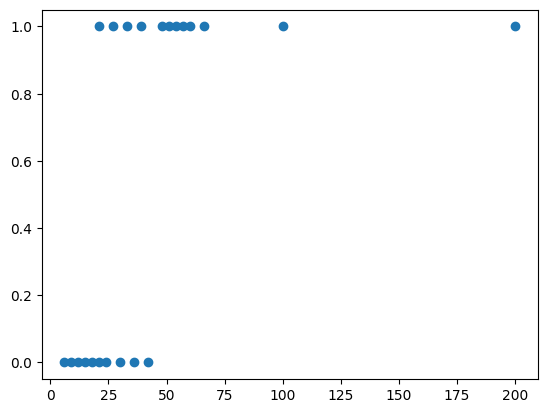

In [3]:
plt.scatter(x,Y)

_Попробуем разделить эти точки прямой линией, отделяющей один класс от другого. 
Модель начинает плохо работать в случае добавления новых точек на больших значениях x:_

In [4]:
a1 = ((x-x.mean())*(Y-Y.mean())).mean()/((x-x.mean())**2).mean()
a0 = Y.mean() - a1*x.mean()
print("Y = ", a0, " + ", a1, " * x")
x_space = np.linspace(6,70,20)
Y_pred = a0.item() + a1.item()*x_space

Y =  0    0.266493
dtype: float64  +  0    0.006333
dtype: float64  * x


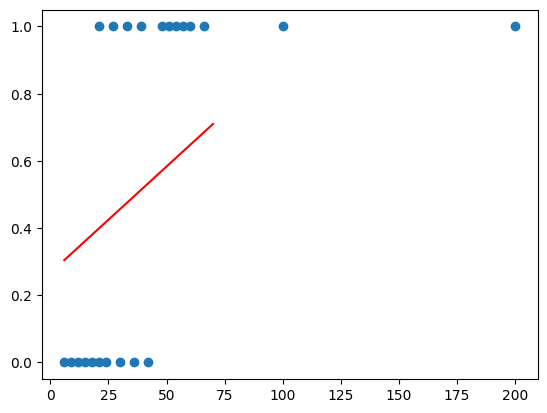

In [5]:
plt.plot(x_space, Y_pred, 'r')
plt.scatter(x, Y)

<h2>Функция логистической регрессии</h2>

__Сигмоида__

Возможное решение упомянутых выше сложностей — пропустить значение линейной регрессии через сигмоиду (sigmoid function), 
которая при любом значении x не выйдет из необходимого нам диапазона от 0 до 1. <br>
<h3>$g(x) = \frac{1}{1+ e^{-x}}$</h3>

 <img src='images/ris1.png' width=320, heigth=240>

<h3>Logistic loss или функция кросс-энтропии</h3>

В модели логистической регрессии мы не можем использовать MSE. Дело в том, 
что если мы поместим результат сигмоиды (представляющей собою нелинейную функцию) в MSE, 
то на выходе получим невыпуклую функцию (non-convex), глобальный минимум которой довольно сложно найти.
 <img src='images/ris2.png' width=520, heigth=240>
    Вместо MSE мы будем использовать функцию логистической ошибки, которую еще называют функцией бинарной кросс-энтропии (log loss, binary cross-entropy loss).

__График и формула функции логистической ошибки__<br>
 <img src='images/ris3.png' width=420, heigth=240>

$J(\theta)=-\frac{1}{n} \sum{y*log(h_{\theta}(x))+(1-y)*log(1-h_{\theta}(x))}$

<h3>Оценка качества модели</h3>

__Матрицa ошибок (confusion matrix)__<br>
 <img src='images/ris4.png' width=420, heigth=240><br>
Доля правильно предсказанных значений называется accuracy. Чтобы ее посчитать, мы берем те значения,
    которые предсказаны верно (TP + TN) и делим на общее количество прогнозов.<br>
    <h3>$accuracy=\frac{TP+TN}{TP+TN+FP+FN}$</h3>

<h2>Конкретизация задачи:</h2>

Реализовать класс модели логистической регрессии с использованием:

а) максимизации логарифмического правдоподобия методом градиентного подъема

б) минимизации функции потерь (кросс-энтропии) методом градиентного спуска

Сравнить результаты (время исполнения и достигнутые значения accuracy и f1) в случаях а и б при одном и том же числе шагов и скорости обучения.

In [6]:
#Реализуем цикл градиентного спуска
class LogisticRegressionGD(object):
    def __init__(self):
        self.a = np.zeros(2).reshape(1, 2)
        
    def sigmoid(self, x):
        return 1/(1 + np.exp(-x @ self.a))
    
    def predict(self, x):
        return self.sigmoid(x)
    
    def coefs(self):
        return self.a
      
    def LogLikelihood(self, x, Y):
        return (Y * np.log(self.predict(x)) + (1 - Y) * np.log(1 - self.predict(x))).sum()

    def CrossEntropy(self, x, Y):
        return (-Y * np.log(self.predict(x)) - (1 - Y) * np.log(1 - self.predict(x))).sum()
    
    def accuracy(self, x, Y):
        return ((self.predict(x) > 0.5)==Y).mean() 

    def fit(self, x, Y, alpha = 0.01, epsylon = 0.01, max_steps = 10000, Rtype = "LL"):
        self.a = np.zeros (x.shape[1]).reshape(x.shape[1],1)
        steps, errors = [], []
        step = 0
        for _ in range(max_steps):
            if Rtype == "LL":
                new_error = self.LogLikelihood(x, Y)
                dT_a = x.T @(Y - self.predict(x)) / x.shape[0]
                self.a += alpha*dT_a
            elif Rtype == "CE":
                new_error = self.CrossEntropy(x, Y)
                #display(new_error)
                dT_a = -x.T @(Y - self.predict(x)) / x.shape[0]
                self.a -= alpha*dT_a
            step += 1
            steps.append(step)
            errors.append(new_error)
            #if new_error < epsylon:
            #    break
        return steps, errors

In [7]:
x_ = x.copy()

import time

intercept = np.ones((x.shape[0], 1))
x_ = pd.DataFrame(np.concatenate((intercept, x), axis = 1))

In [8]:
start_time_CE = time.time()
regr_CE = LogisticRegressionGD()
steps_CE, errors_CE =  regr_CE.fit(x_, Y, alpha = 0.01, epsylon = 0.01, max_steps = 10000, Rtype = "CE") 

display(f"Время обучения: {time.time() - start_time_CE} сек.")

start_time_LL = time.time()
regr_LL = LogisticRegressionGD()
steps_LL, errors_LL =  regr_LL.fit(x_, Y, alpha = 0.01, epsylon = 0.01, max_steps = 10000, Rtype = "LL") 

display(f"Время обучения: {time.time() - start_time_LL} сек.")

'Время обучения: 31.255775451660156 сек.'

'Время обучения: 32.428428649902344 сек.'

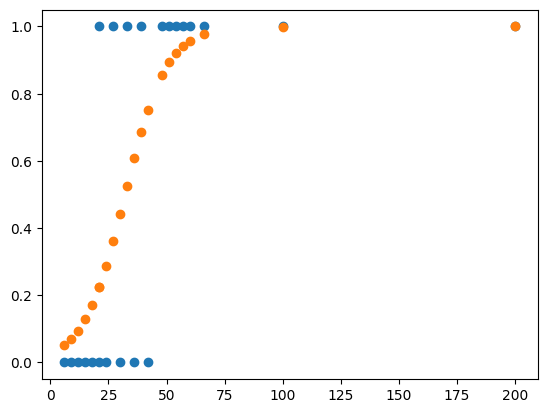

In [9]:
Y_Pred = regr_CE.predict(x_)
plt.scatter(x, Y)
plt.scatter(x, Y_Pred)

In [10]:
display(regr_CE.coefs())
#display(x_)

,0
0,-3.599111
1,0.112160


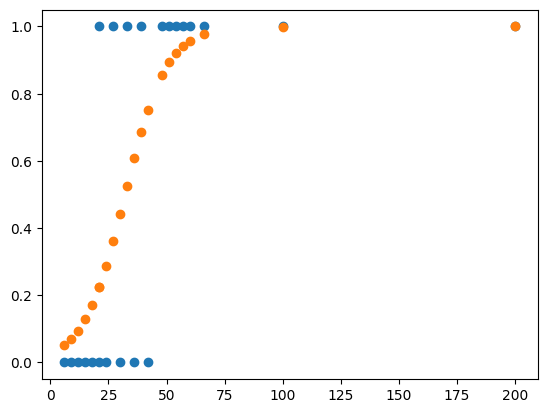

In [11]:
Y_Pred = regr_LL.predict(x_)
plt.scatter(x, Y)
plt.scatter(x, Y_Pred)

In [12]:
display(regr_LL.coefs())
#display(x_)

,0
0,-3.599111
1,0.112160


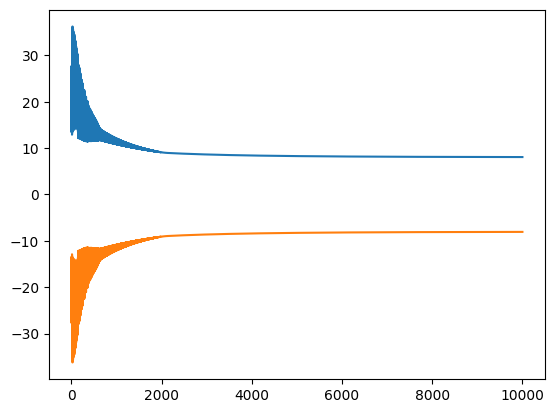

In [13]:
plt.plot(steps_CE, errors_CE)
plt.plot(steps_LL, errors_LL)

In [14]:
print(regr_CE.accuracy(x_, Y))
print(regr_LL.accuracy(x_, Y))

0    0.818182
dtype: float64
0    0.818182
dtype: float64


Реализовать расчеты способами а и б для набора данных из файла insclass_train.csv/
Для 151 406 договоров страхования транспортных средств известны значения ряда признаков, в том числе пол, возраст, стаж вождения и коэффициент бонус-малус водителя, тип, марка, модель, год выпуска, страна – производитель, мощность и объем двигателя, а также признак target, равный 1, если заключение договора с клиентом является рисковым, и 0 в противном случае (файл insclass_train.csv).

Требуется построить модель, предсказывающую значение признака target для 22 624 договоров из тестового набора данных (файл insclass_test.csv).

В обучающем наборе данных для каждого договора известны следующие поля:

variable_1 - агрегированный коэффициент бонус-малус (повышающий или понижающий стоимость полиса в зависимости от аварийности в предыдущие периоды);
variable_2 - индикатор расторжения договора по инициативе страхователя (клиента);
variable_3 - индикатор расторжения договора по инициативе страховщика (страховой компании);
variable_4 - идентификатор года выпуска транспортного средства;
variable_5 - идентификатор страны - производителя транспортного средства;
variable_6 - мощность двигателя в лошадиных силах;
variable_7 - объем двигателя в куб. см;
variable_8 - идентификатор стороны расположения руля (левый или правый);
variable_9 - пробег транспортного средства, покрываемый гарантией производителя;
variable_10 - индикатор действия гарантии на транспортное средство;
variable_11 - "мультидрайв" - индикатор допуска к управлению транспортным средством более одного водителя;
variable_12 - возраст транспортного средства (в мес.);
variable_13 - возраст водителя с максимальным стажем;
variable_14 - коэффициент возраст-стаж;
variable_15 - коэффициент краткосрочности;
variable_16 - коэффициент мощности;
variable_17 - коэффициент "мультидрайв";
variable_18 - территориальный коэффициент;
variable_19 - коэффициент "КНДР";
variable_20 - идентификатор канала продаж;
variable_21 - марка транспортного средства;
variable_22 - модель транспортного средства;
variable_23 - индикатор отечественных транспортных средств;
variable_24 - пол водителя с максимальным коэффициентом "возраст-стаж";
variable_25 - индикатор пролонгации;
variable_26 - индикатор совпадения собственника транспортного средства и водителя;
variable_27 - стаж водителя с максимальным коэффициентом "возраст-стаж";
variable_28 - тип транспортного средства;
target - класс риска, равный 1, если заключение договора с клиентом является рисковым, и 0 в противном случае.

In [15]:
from math import ceil
from colorama import Fore, Style
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from numpy.typing import NDArray
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.preprocessing import LabelEncoder

In [16]:
def evaluate_classification_models(
    predictions: dict[str, NDArray[np.float64]], y: NDArray[np.float64]
) -> pd.DataFrame:
    """Evaluate multiple classification model predictions on the provided dataset.

    Args:
        predictions (dict[str, NDArray[np.float64]]): Dictionary mapping model names
            to predicted target arrays for the dataset.
        y (NDArray[np.float64]): True binary target values of shape (n_samples,).

    Returns:
        pd.DataFrame: DataFrame containing classification metrics — Accuracy, Precision,
            Recall, F1-score, and ROC AUC — for each model. Columns correspond to
            model names, rows correspond to the metric names.
    """
    evaluations = pd.DataFrame(
        columns=predictions.keys(),
        index=["Accuracy", "Precision", "Recall", "F1-score", "ROC AUC"],
    )

    for name, y_pred in predictions.items():
        y_pred_bin = y_pred > 0.5
        accuracy = accuracy_score(y, y_pred_bin)
        precision = precision_score(y, y_pred_bin)
        recall = recall_score(y, y_pred_bin)
        f1 = f1_score(y, y_pred_bin)
        roc_auc = roc_auc_score(y, y_pred)

        evaluations.loc[:, name] = [accuracy, precision, recall, f1, roc_auc]

    return evaluations.astype(float)

In [17]:
def plot_confusion_matrices(
    predictions: dict[str, NDArray[np.int64]],
    y_true: NDArray[np.int64],
    n_cols: int = 2,
) -> None:
    """Plot confusion matrices for multiple classification models.

    Each confusion matrix compares the true labels to predictions from one model.
    The plots are arranged in a grid layout for easy comparison.

    Args:
        predictions (dict[str, NDArray[np.int64]]): A dictionary mapping model names to
            their predicted labels (1D array of shape (n_samples,)).
        y_true (NDArray[np.int64]): True class labels (1D array of shape (n_samples,)).
        n_cols (int, optional): Number of columns in the subplot grid layout.
            Default is 2.
    """
    n_models = len(predictions)
    n_cols = min(n_models, n_cols)
    n_rows = ceil(n_models / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
    axes = np.array(axes).reshape(-1)

    for ax, (name, y_pred) in zip(axes, predictions.items(), strict=False):
        conf_matrix = confusion_matrix(y_true, y_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
        ax.set_xlabel("Predicted Labels")
        ax.set_ylabel("True Labels")
        ax.set_title(name)

    for i in range(n_models, len(axes)):
        fig.delaxes(axes[i])

    plt.tight_layout()
    plt.show() 

In [18]:
df = pd.read_csv("insclass_train.csv")

In [19]:
print(f"{Fore.MAGENTA}DataFrame Info:{Style.RESET_ALL}")
df.info()

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 151406 entries, 0 to 151405
Data columns (total 29 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   variable_1   151406 non-null  object 
 1   variable_2   151406 non-null  int64  
 2   variable_3   151406 non-null  int64  
 3   variable_4   151406 non-null  int64  
 4   variable_5   151406 non-null  object 
 5   variable_6   151295 non-null  float64
 6   variable_7   55767 non-null   float64
 7   variable_8   121507 non-null  float64
 8   variable_9   16970 non-null   float64
 9   variable_10  151406 non-null  int64  
 10  variable_11  151406 non-null  int64  
 11  variable_12  149878 non-null  float64
 12  variable_13  149749 non-null  float64
 13  variable_14  148479 non-null  float64
 14  variable_15  13 non-null      float64
 15  variable_16  151394 non-null  float64
 16  variable_17  151394 non-null  float64
 17  variable_18  151394 non-null  float64
 18  variable

In [20]:
print(f"{Fore.GREEN}DataFrame Description:{Style.RESET_ALL}")
print(df.describe(include="all"))

DataFrame Description:
       variable_1     variable_2  variable_3     variable_4 variable_5  \
count      151406  151406.000000    151406.0  151406.000000     151406   
unique         15            NaN         NaN            NaN         39   
top          w200            NaN         NaN            NaN         q4   
freq        59216            NaN         NaN            NaN      32799   
mean          NaN       0.017047         0.0      11.307676        NaN   
std           NaN       0.129446         0.0       6.925851        NaN   
min           NaN       0.000000         0.0       2.000000        NaN   
25%           NaN       0.000000         0.0       6.000000        NaN   
50%           NaN       0.000000         0.0      10.000000        NaN   
75%           NaN       0.000000         0.0      14.000000        NaN   
max           NaN       1.000000         0.0      80.000000        NaN   

           variable_6    variable_7     variable_8    variable_9  \
count   151295.00000

In [21]:
print(f"{Fore.YELLOW}First Rows of DataFrame:{Style.RESET_ALL}")
print(df.head())

First Rows of DataFrame:
  variable_1  variable_2  variable_3  variable_4 variable_5  variable_6  \
0       w200           0           0          14         q2        98.0   
1       w160           0           0           7        q11       106.0   
2       w200           0           0           4         q3       123.0   
3       w200           0           0           9         q3       102.0   
4       w200           0           0          18        q20       117.0   

   variable_7  variable_8  variable_9  variable_10  ...  variable_20  \
0         NaN         0.0         NaN            0  ...            C   
1         NaN         0.0         NaN            0  ...            C   
2         NaN         0.0         NaN            0  ...            B   
3         NaN         0.0         NaN            0  ...            C   
4         NaN         0.0         NaN            0  ...            C   

   variable_21  variable_22  variable_23  variable_24  variable_25  \
0           j2       

In [22]:
print(f"{Fore.RED}Missing Values in Each Column:{Style.RESET_ALL}")
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100
missing_df = pd.DataFrame({"Missing Count": missing, "Missing %": missing_percent})
print(missing_df)

Missing Values in Each Column:
             Missing Count  Missing %
variable_1               0   0.000000
variable_2               0   0.000000
variable_3               0   0.000000
variable_4               0   0.000000
variable_5               0   0.000000
variable_6             111   0.073313
variable_7           95639  63.167246
variable_8           29899  19.747566
variable_9          134436  88.791726
variable_10              0   0.000000
variable_11              0   0.000000
variable_12           1528   1.009207
variable_13           1657   1.094408
variable_14           2927   1.933213
variable_15         151393  99.991414
variable_16             12   0.007926
variable_17             12   0.007926
variable_18             12   0.007926
variable_19              0   0.000000
variable_20              1   0.000660
variable_21              0   0.000000
variable_22              0   0.000000
variable_23              0   0.000000
variable_24           2207   1.457670
variable_25        

In [23]:
features = [
    'variable_1', 'variable_2', 'variable_3', 'variable_4', 'variable_5',
    'variable_6', 'variable_7', 'variable_8', 'variable_9', 'variable_10',
    'variable_11', 'variable_12', 'variable_13', 'variable_14',
    'variable_15', 'variable_16', 'variable_17', 'variable_18',
    'variable_19', 'variable_20', 'variable_21', 'variable_22',
    'variable_23', 'variable_24', 'variable_25', 'variable_26',
    'variable_27', 'variable_28'
]

categorical_features = [
    'variable_1', 'variable_2', 'variable_3', 'variable_4', 'variable_5',
    'variable_8', 'variable_10', 'variable_11', 'variable_20',
    'variable_21', 'variable_22', 'variable_23', 'variable_24',
    'variable_25', 'variable_26', 'variable_28'
]

numerical_features = [
    'variable_6', 'variable_7', 'variable_9', 'variable_12', 
    'variable_13', 'variable_14', 'variable_15', 'variable_16',
    'variable_17', 'variable_18', 'variable_19', 'variable_27',
]

for feature in numerical_features:
    df[feature] = df[feature].fillna(0)

le = LabelEncoder()
for feature in categorical_features:
    df[feature] = le.fit_transform(df[feature])

X, y = df[features], df["target"]
X_np = X.values.astype(float)
y_np = y.values.reshape(-1, 1) 

X_train, X_val, y_train, y_val = train_test_split(X_np, y_np, test_size=0.2, random_state=42)

In [24]:
regr_CE_model = LogisticRegressionGD()
_, _ = regr_CE_model.fit(X_train, y_train, alpha=0.01, epsylon=0.01, max_steps=10000, Rtype="CE") 

regr_LL_model = LogisticRegressionGD()
_, _ = regr_LL_model.fit(X_train, y_train, alpha=0.01, epsylon=0.01, max_steps=10000, Rtype="LL") 

C:\Users\NKTKLN\AppData\Local\Temp\ipykernel_13988\1826893845.py:7: RuntimeWarning: overflow encountered in exp
  return 1/(1 + np.exp(-x @ self.a))
C:\Users\NKTKLN\AppData\Local\Temp\ipykernel_13988\1826893845.py:19: RuntimeWarning: divide by zero encountered in log
  return (-Y * np.log(self.predict(x)) - (1 - Y) * np.log(1 - self.predict(x))).sum()
C:\Users\NKTKLN\AppData\Local\Temp\ipykernel_13988\1826893845.py:19: RuntimeWarning: invalid value encountered in multiply
  return (-Y * np.log(self.predict(x)) - (1 - Y) * np.log(1 - self.predict(x))).sum()
C:\Users\NKTKLN\AppData\Local\Temp\ipykernel_13988\1826893845.py:16: RuntimeWarning: divide by zero encountered in log
  return (Y * np.log(self.predict(x)) + (1 - Y) * np.log(1 - self.predict(x))).sum()
C:\Users\NKTKLN\AppData\Local\Temp\ipykernel_13988\1826893845.py:16: RuntimeWarning: invalid value encountered in multiply
  return (Y * np.log(self.predict(x)) + (1 - Y) * np.log(1 - self.predict(x))).sum()


In [25]:
probs = {
    "regr_CE": regr_CE_model.predict(X_val),
    "regr_LL": regr_LL_model.predict(X_val)
}

preds = {
    "regr_CE": regr_CE_model.predict(X_val) > 0.5,
    "regr_LL": regr_LL_model.predict(X_val) > 0.5
}

C:\Users\NKTKLN\AppData\Local\Temp\ipykernel_13988\1826893845.py:7: RuntimeWarning: overflow encountered in exp
  return 1/(1 + np.exp(-x @ self.a))


In [26]:
evaluate_classification_models(probs, y_val)

,regr_CE,regr_LL
Accuracy,0.903837,0.903837
Precision,0.690909,0.690909
Recall,0.012956,0.012956
F1-score,0.025435,0.025435
ROC AUC,0.507885,0.507885


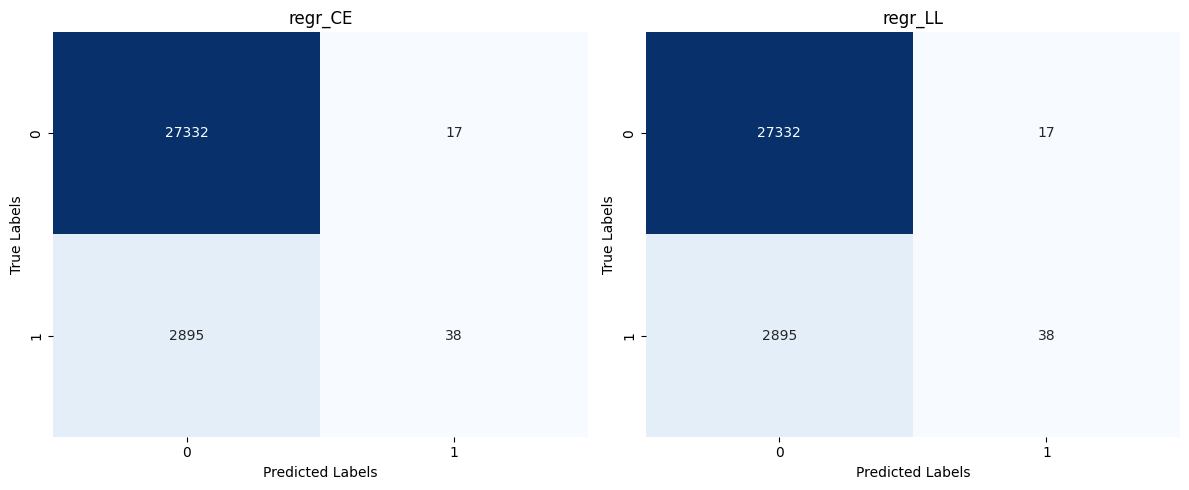

In [27]:
plot_confusion_matrices(preds, y_val)